# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering

**Name:** Abhilash Reddy Marthala  
**Course:** MSCS 634 – Advanced Big Data and Data Mining

## Objective
Apply Hierarchical Clustering and DBSCAN to the Wine dataset,
explore different parameter settings, visualize the clusters,
and compare their clustering quality.

## 1. Data Preparation and Exploration

The Wine dataset contains chemical measurements for 178 wine samples
across 13 numerical features. The known wine classes are used only
to evaluate the clustering results, not to train the clustering models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    homogeneity_score,
    completeness_score
)
from scipy.cluster.hierarchy import linkage, dendrogram

wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset shape:", X.shape)

print("\nFirst five rows:")
display(X.head())

print("\nDataset information:")
X.info()

print("\nSummary statistics:")
display(X.describe())

print("\nMissing values:")
print(X.isna().sum())

print("\nKnown class counts:")
print(pd.Series(y).value_counts().sort_index())

Dataset shape: (178, 13)

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



Missing values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Known class counts:
0    59
1    71
2    48
Name: count, dtype: int64


In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

display(scaled_df.head())

print("Feature means:")
print(np.round(X_scaled.mean(axis=0), 3))

print("\nFeature standard deviations:")
print(np.round(X_scaled.std(axis=0), 3))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


Feature means:
[-0. -0. -0. -0. -0.  0. -0.  0. -0.  0.  0.  0. -0.]

Feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Feature Standardization

The features have different measurement scales. StandardScaler
transforms them to approximately zero mean and unit standard
deviation so that features with larger numerical values do not
dominate the clustering distance calculations.

Variance explained by two components: 55.41%


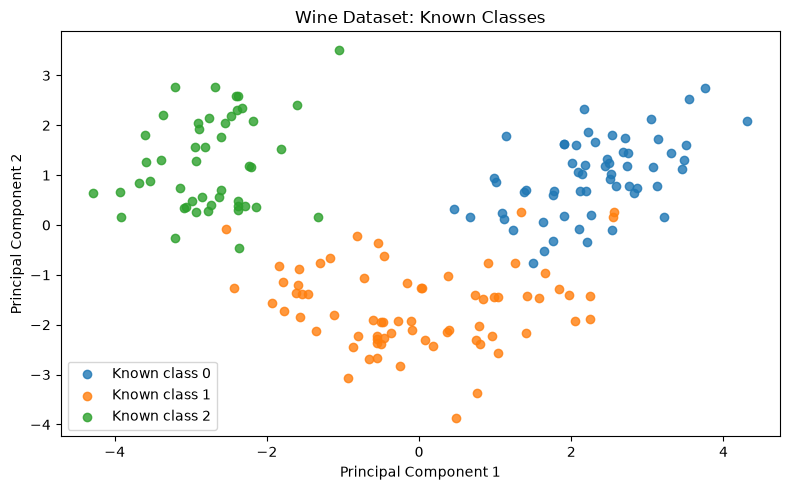

In [3]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by two components:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

plt.figure(figsize=(8, 5))

for label in np.unique(y):
    mask = y == label

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Known class {label}",
        alpha=0.8
    )

plt.title("Wine Dataset: Known Classes")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

## PCA Visualization

The first two principal components explain approximately 55.4% of
the total variance. PCA is used only for visualization; clustering
will use all 13 standardized features.

The colors represent the known wine classes, not predicted clusters.
These class labels are used for evaluation, not for fitting the models.

## Hierarchical Clustering

Agglomerative Clustering progressively merges observations into groups.
Ward linkage minimizes the increase in within-cluster variance.

I tested two through six clusters using all 13 standardized features.
PCA coordinates are used only to visualize the resulting clusters.

In [4]:
hierarchical_results = []
hierarchical_labels = {}

for k in range(2, 7):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)
    hierarchical_labels[k] = labels

    hierarchical_results.append({
        "n_clusters": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Homogeneity": homogeneity_score(y, labels),
        "Completeness": completeness_score(y, labels)
    })

hierarchical_df = pd.DataFrame(hierarchical_results)
display(hierarchical_df.round(4))

,n_clusters,Silhouette,Homogeneity,Completeness
0,2,0.2670,0.4441,0.7745
1,3,0.2774,0.7904,0.7825
2,4,0.2258,0.7904,0.6490
3,5,0.1867,0.8106,0.5762
4,6,0.1797,0.8348,0.5530


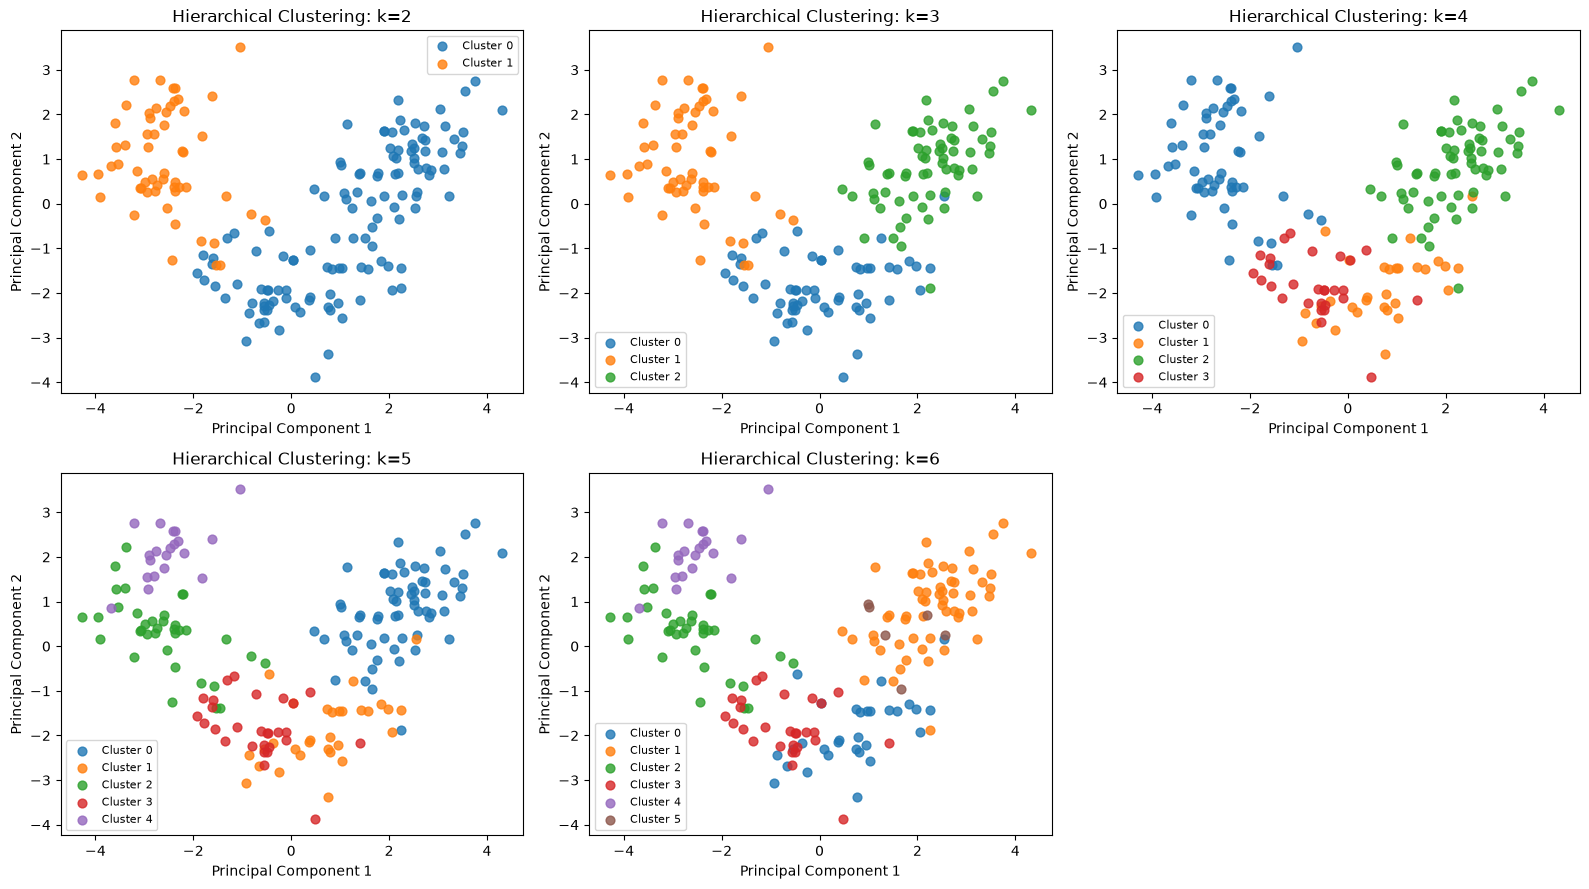

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, k in zip(axes.flat, range(2, 7)):
    labels = hierarchical_labels[k]

    for cluster in np.unique(labels):
        mask = labels == cluster

        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            label=f"Cluster {cluster}",
            alpha=0.8,
            s=40
        )

    ax.set_title(f"Hierarchical Clustering: k={k}")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(fontsize=8)

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### Interpretation

Three clusters produced the highest silhouette score among the tested
settings, approximately 0.2774. Homogeneity was approximately 0.7904,
and completeness was approximately 0.7825.

Increasing the cluster count beyond three reduced the silhouette
score, indicating less clearly separated groups under this metric.
All 178 observations were assigned to clusters.

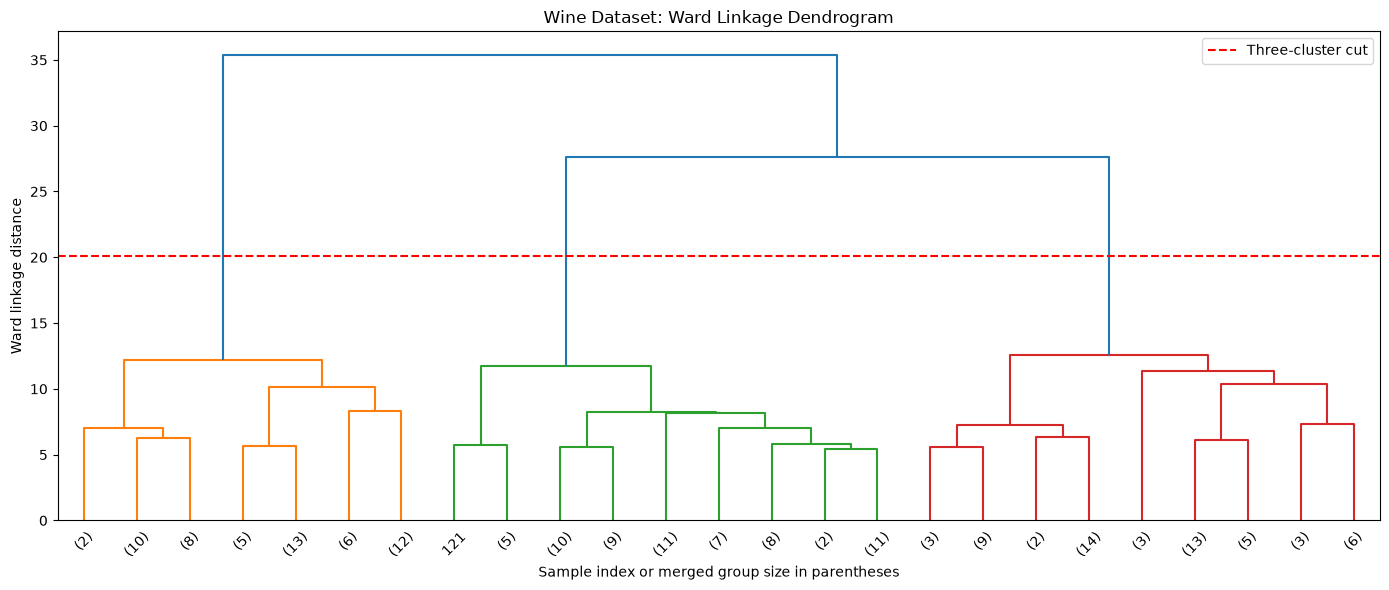

In [6]:
Z = linkage(X_scaled, method="ward")

# Choose a cut height that produces three clusters.
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=25,
    show_leaf_counts=True,
    color_threshold=cut_height
)

plt.axhline(
    y=cut_height,
    color="red",
    linestyle="--",
    label="Three-cluster cut"
)

plt.title("Wine Dataset: Ward Linkage Dendrogram")
plt.xlabel("Sample index or merged group size in parentheses")
plt.ylabel("Ward linkage distance")
plt.legend()
plt.tight_layout()
plt.show()

### Dendrogram Interpretation

The dendrogram shows how observations and smaller groups are
progressively merged. Higher merge heights indicate that more
dissimilar groups are being combined under Ward linkage.

The red dashed line illustrates a cut that produces three clusters.
This choice is also supported by the silhouette comparison, where
three clusters gave the highest score among the tested settings.

The diagram is truncated to the final 25 groups for readability.
Some leaves represent multiple observations, with their sizes
shown in parentheses.

## DBSCAN Clustering

DBSCAN groups observations in dense regions and labels noise as -1.

The eps parameter controls the neighborhood radius. The min_samples
parameter specifies the minimum neighborhood count, including the
point itself, required for a core point.

Silhouette scores exclude noise points. Homogeneity and completeness
include all observations, treating noise as one predicted group.
Coverage reports the proportion of observations assigned to clusters.

In [7]:
eps_values = [0.5, 1.5, 2.0, 2.25, 2.5, 2.75, 3.0, 3.5, 4.0]
min_samples_values = [3, 5, 10]

dbscan_results = []

for min_samples in min_samples_values:
    for eps in eps_values:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        # Exclude noise when counting clusters and computing silhouette.
        mask = labels != -1
        n_clusters = len(np.unique(labels[mask]))

        if 2 <= n_clusters < mask.sum():
            silhouette = silhouette_score(
                X_scaled[mask],
                labels[mask]
            )
        else:
            silhouette = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise": int((~mask).sum()),
            "Coverage": mask.mean(),
            "Silhouette": silhouette,
            "Homogeneity": homogeneity_score(y, labels),
            "Completeness": completeness_score(y, labels)
        })

dbscan_df = pd.DataFrame(dbscan_results)
display(dbscan_df.round(4))

,eps,min_samples,Clusters,Noise,Coverage,Silhouette,Homogeneity,Completeness
0,0.50,3,0,178,0.0000,NaN,0.0000,1.0000
1,1.50,3,8,147,0.1742,0.3311,0.1892,0.2510
2,2.00,3,5,64,0.6404,0.2113,0.4423,0.3724
3,2.25,3,2,37,0.7921,0.3313,0.4934,0.5368
4,2.50,3,1,23,0.8708,NaN,0.0668,0.1885
5,2.75,3,1,16,0.9101,NaN,0.0530,0.1904
6,3.00,3,2,7,0.9607,0.2392,0.0311,0.1347
7,3.50,3,2,3,0.9831,0.2308,0.0293,0.1866
8,4.00,3,2,0,1.0000,0.2225,0.0145,0.1837
9,0.50,5,0,178,0.0000,NaN,0.0000,1.0000


### DBSCAN Parameter Results

With eps=0.5 and min_samples=5, all 178 observations were classified
as noise.

With eps=2.25 and min_samples=5, DBSCAN produced two clusters and
46 noise points. Its non-noise silhouette score was approximately
0.3371, with coverage of approximately 74.2%.

Increasing eps to 2.5 with min_samples=5 produced one cluster and
24 noise points. Silhouette was undefined because only one non-noise
cluster remained.

These results show that the neighborhood radius strongly influences
cluster formation and the number of noise observations.

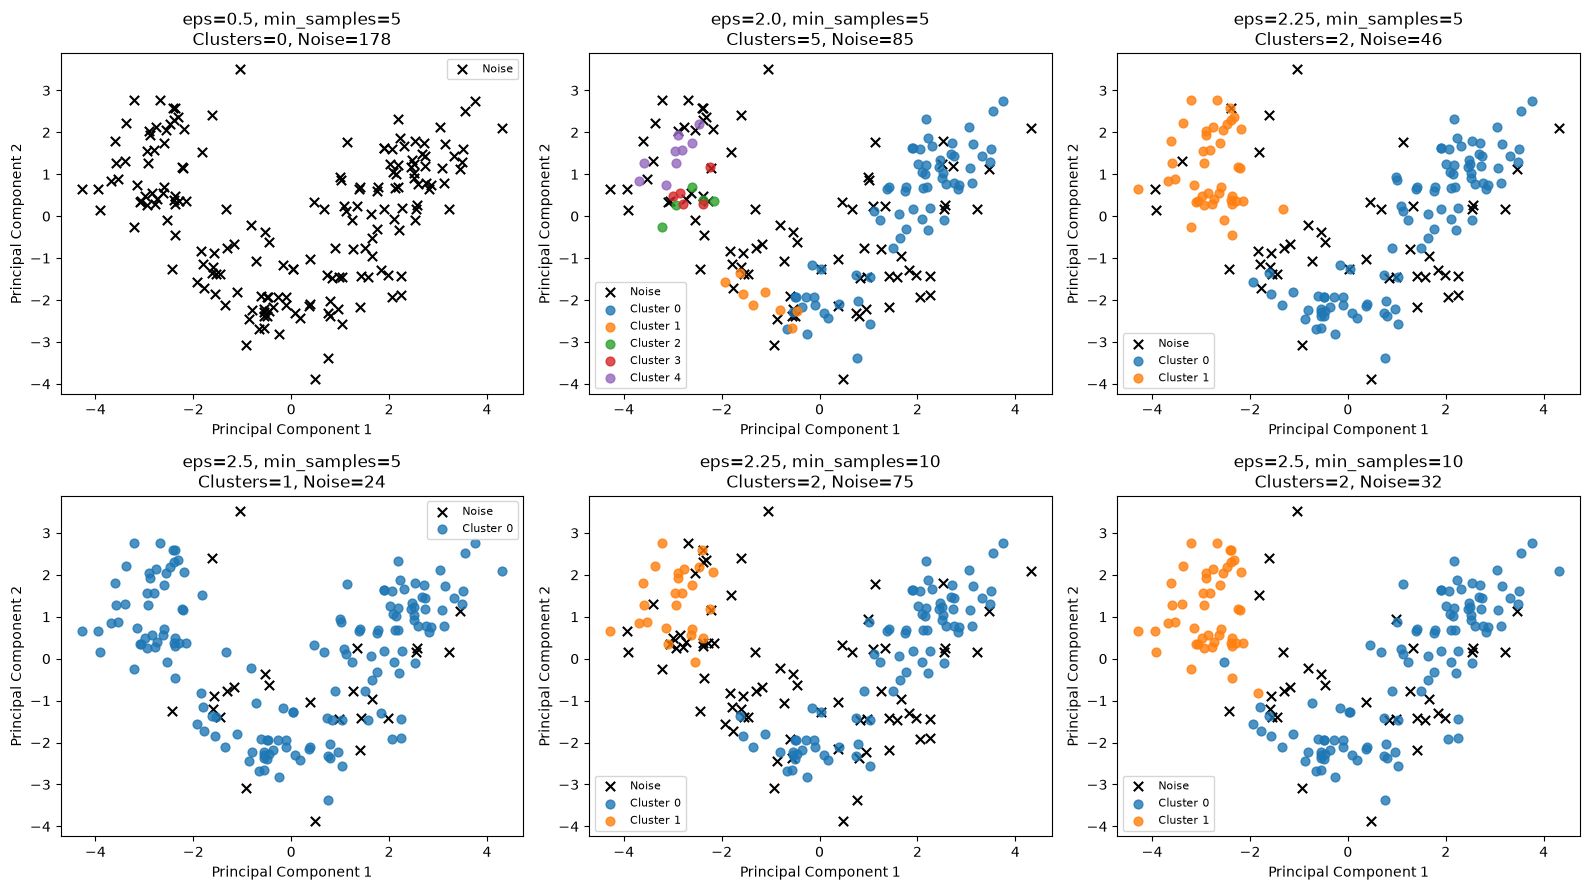

In [8]:
settings = [
    (0.5, 5),
    (2.0, 5),
    (2.25, 5),
    (2.5, 5),
    (2.25, 10),
    (2.5, 10)
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (eps, min_samples) in zip(axes.flat, settings):
    labels = DBSCAN(
        eps=eps,
        min_samples=min_samples
    ).fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})
    n_noise = int((labels == -1).sum())

    for label in sorted(np.unique(labels)):
        mask = labels == label

        if label == -1:
            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                color="black",
                marker="x",
                s=45,
                label="Noise"
            )
        else:
            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                s=40,
                alpha=0.8,
                label=f"Cluster {label}"
            )

    ax.set_title(
        f"eps={eps}, min_samples={min_samples}\n"
        f"Clusters={n_clusters}, Noise={n_noise}"
    )
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### DBSCAN Visualization Insights

The plots show how parameter choices affect cluster membership
and noise detection. Black crosses represent noise observations.

With eps=0.5 and min_samples=5, every observation is noise.
Increasing eps allows more observations to join clusters, but
larger neighborhoods can also merge groups.

At eps=2.25, increasing min_samples from 5 to 10 increases the
noise count from 46 to 75. This happens because the higher
min_samples value requires denser neighborhoods.

These plots use two PCA components for display, while DBSCAN
uses all 13 standardized features.

In [9]:
# Compare Ward with 3 clusters against a representative DBSCAN setting.
hierarchical_row = hierarchical_df.loc[
    hierarchical_df["n_clusters"] == 3
].iloc[0]

dbscan_row = dbscan_df.loc[
    (dbscan_df["eps"] == 2.25) &
    (dbscan_df["min_samples"] == 5)
].iloc[0]

comparison = pd.DataFrame([
    {
        "Algorithm": "Hierarchical: Ward, k=3",
        "Clusters": 3,
        "Noise": 0,
        "Coverage": 1.0,
        "Silhouette": hierarchical_row["Silhouette"],
        "Homogeneity": hierarchical_row["Homogeneity"],
        "Completeness": hierarchical_row["Completeness"]
    },
    {
        "Algorithm": "DBSCAN: eps=2.25, min_samples=5",
        "Clusters": int(dbscan_row["Clusters"]),
        "Noise": int(dbscan_row["Noise"]),
        "Coverage": dbscan_row["Coverage"],
        "Silhouette": dbscan_row["Silhouette"],
        "Homogeneity": dbscan_row["Homogeneity"],
        "Completeness": dbscan_row["Completeness"]
    }
])

display(comparison.round(4))

,Algorithm,Clusters,Noise,Coverage,Silhouette,Homogeneity,Completeness
0,"Hierarchical: Ward, k=3",3,0,1.0000,0.2774,0.7904,0.7825
1,"DBSCAN: eps=2.25, min_samples=5",2,46,0.7416,0.3371,0.4722,0.4953


## Analysis and Insights

### Comparison of Algorithms

Hierarchical Clustering with three clusters assigned all 178 samples
to groups and achieved a silhouette score of approximately 0.2774.

DBSCAN with eps=2.25 and min_samples=5 identified two clusters and
46 noise points. Its non-noise silhouette score was approximately
0.3371, with coverage of approximately 74.2%.

The higher DBSCAN silhouette score does not automatically mean
better overall clustering. It excludes noise samples, whereas
the Hierarchical score includes all observations.

The DBSCAN setting was selected as a representative example of
the tradeoff between separation and coverage, not as a universally
optimal configuration.

### Influence of Parameters

For Hierarchical Clustering, three clusters produced the highest
silhouette score among the tested values. Increasing the cluster
count beyond three reduced the score.

DBSCAN was sensitive to eps and min_samples. Small eps values
produced excessive noise, while larger values often merged groups.
Increasing min_samples required denser neighborhoods and could
leave more observations classified as noise.

### Strengths and Weaknesses

Hierarchical Clustering provided an interpretable dendrogram and
assigned every observation to a cluster. However, the final partition
required a cluster-count choice, and potential outliers were still
assigned to groups.

DBSCAN identified noise and did not require a predefined cluster
count. However, selecting suitable density parameters was challenging.
Several tested settings produced either excessive noise or only
one cluster.

### Conclusion

Within the tested configurations, Ward Hierarchical Clustering with
three clusters was more useful for obtaining a complete grouping
of the Wine dataset. DBSCAN was useful for exploring dense regions
and identifying observations outside those regions.

These findings are specific to this dataset, preprocessing method,
and parameter grid.